# Klasifikasi Penyakit Daun Tanaman (Versi 4 Kelas)
## Machine Learning Competition — Informatics Festival (I-Fest) 6.0
### HIMIF Universitas Multi Data Palembang

---

## Identitas Kelompok

| Atribut        | Detail                              |
|----------------|-------------------------------------|
| **Nama Tim**   | Belum Kepikiran                     |
| **Kompetisi**  | Machine Learning                    |
| **Ketua**      | Elvionita Sahara                    |
| **Anggota 1**  | M. Ma'ruf Qomaruddin Kafi           |

---

## Deskripsi Proyek

Notebook ini berisi solusi untuk klasifikasi **penyakit daun** pada empat jenis tanaman:
- **Kentang**
- **Lemon**
- **Teh**
- **Tomat**

Model dibangun menggunakan **Convolutional Neural Network (CNN) dari nol** (tanpa pretrained model / transfer learning), sesuai ketentuan kompetisi. Total terdapat **27 kelas** penyakit dan kondisi daun yang diklasifikasikan.

---

## Struktur Folder Google Drive
sebelum melakukan runing cell code dibawah, usahakan untuk membuat struktur folder seperti berikut
```
MACHINE LEARNING_IFEST6.0_belum kepikiran/
├── dataset/
│   ├── raw/
│   │   └── archive_folder.zip                             -> Dataset mentah (archive_folder.zip) yang belum di-split
│   └── split/                                             -> Hasil split train (80%), val (10%), test (10%) yang merupakan hasil generate cell 5 dan hasil output dari cell 10 dan disimpan dengan nama file split_dataset_backup
├── notebooks/
│   └── MACHINE LEARNING_IFEST6.0_belum kepikiran_4 Kelas.ipynb     -> File notebook utama pengerjaan
└── models/
    └── best_model.h5                                      -> Model terbaik (disimpan otomatis via ModelCheckpoint)
```

adapun untuk isi file archive_folder.zip adalah sebagai berikut:
```
archive_folder
├── Kentang
│  ├── Early_blight
│   ├── healthy
│   └── Late_blight
├── Lemon
│   ├── Anthracnose
│   ├── Bacterial Blight
│   ├── Citrus Canker
│   ├── Curl Virus
│   ├── Deficiency Leaf
│   ├── Dry Leaf
│   ├── Healthy Leaf
│   ├── Sooty Mould
│   └── Spider Mites
├── Teh
│   ├── algal leaf
│   ├── bird eye spot
│   ├── brown blight
│   ├── gray blight
│   └── healthy
└── Tomat
    ├── Bacterial_spot
    ├── Early_blight
    ├── healthy
    ├── Late_blight
    ├── Leaf_Mold
    ├── Septoria_leaf_spot
    ├── Spider_mites Two-spotted_spider_mite
    ├── Target_Spot
    ├── Tomato_mosaic_virus
    └── Tomato_Yellow_Leaf_Curl_Virus
```
dimana tiap folder berisi file gambar daun dengan kategori masing-masing.

---

## Cara Menjalankan Notebook

Ikuti langkah-langkah berikut **secara berurutan**:

| Cell | Fungsi |
|------|--------|
| **Cell 1** | Dokumentasi (ini) dimohon untuk membaca dahulu sebelum memulai |
| **Cell 2** | Mount Google Drive |
| **Cell 3** | Ekstrak dataset dari `archive_folder.zip` |
| **Cell 4** | Eksplorasi data (EDA) & visualisasi sebaran kelas |
| **Cell 5** | Split dataset -> train / val / test |
| **Cell 6** | Preprocessing & augmentasi data |
| **Cell 7** | Membangun arsitektur CNN |
| **Cell 8** | Training model |
| **Cell 9** | Evaluasi model (akurasi, confusion matrix, classification report) |
| **Cell 10** | *(Opsional)* Backup split dataset ke Google Drive |
| **Cell 11** | Menyimpan Model Final & Download |
| **Cell 12** | Hasil Analisis & Kesimpulan |

> **Penting:** Pastikan Google Drive sudah ter-mount sebelum menjalankan Cell 3 ke atas.
> Jalankan setiap cell **satu per satu** dan tunggu hingga selesai sebelum lanjut ke cell berikutnya.

---

## Pendekatan Teknis

- **Arsitektur:** Custom CNN 4 layer konvolusi (32 → 64 → 128 → 256 filter)
- **Optimizer:** Adam (lr=0.001) dengan Early Stopping (patience=5)
- **Augmentasi:** Rotasi, flip, zoom, shift — hanya pada data train
- **Input size:** 150×150 piksel, 3 channel (RGB)
- **Output:** 27 kelas (Softmax)
- **Framework:** TensorFlow / Keras

---

*Notebook ini merupakan karya orisinal tim **Belum Kepikiran** untuk kompetisi I-Fest 6.0.*

In [ ]:
# ============================================================
# CELL 2 — Mount Google Drive
# Google Colab tidak bisa mengakses file di Drive secara
# langsung tanpa proses mount terlebih dahulu.
# ============================================================

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive berhasil di-mount!")
print("Drive tersedia di: /content/drive/MyDrive/")

Mounted at /content/drive
Google Drive berhasil di-mount!
Drive tersedia di: /content/drive/MyDrive/


In [ ]:
# ============================================================
# CELL 3 — Ekstrak archive_folder.zip dari Google Drive
# Menggunakan try-except untuk memastikan file tersedia sebelum proses ekstrak dijalankan
# ============================================================

import os
import zipfile

# Path sumber file zip di Google Drive
ZIP_PATH = "/content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/dataset/raw/archive_folder.zip"

# Path tujuan ekstraksi di lokal Colab
EXTRACT_PATH = "/content/MACHINE LEARNING_IFEST6.0_belum kepikiran/dataset/raw"

# Buat folder tujuan jika belum ada
os.makedirs(EXTRACT_PATH, exist_ok=True)

try:
    # Cek apakah file zip tersedia di Drive
    if not os.path.exists(ZIP_PATH):
        raise FileNotFoundError(
            f"File tidak ditemukan di path berikut:\n {ZIP_PATH}\n"
            f"Pastikan file archive_folder.zip sudah ada di Google Drive dan Drive sudah ter-mount (Cell 2)."
        )

    print(f"File ditemukan: {ZIP_PATH}")
    print(f"Mengekstrak dataset ke: {EXTRACT_PATH} ...")

    # Ekstrak zip dengan flag -q (quiet) agar tidak print satu per satu
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)

    print("Ekstraksi berhasil!")
    print(f"Dataset tersedia di: {EXTRACT_PATH}")

except FileNotFoundError as e:
    print(str(e))

except zipfile.BadZipFile:
    print("Error: File zip rusak atau tidak valid. Coba upload ulang archive_folder.zip ke Drive.")

except Exception as e:
    print(f"Terjadi error tak terduga: {e}")

File ditemukan: /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/dataset/raw/archive_folder.zip
Mengekstrak dataset ke: /content/MACHINE LEARNING_IFEST6.0_belum kepikiran/dataset/raw ...
Ekstraksi berhasil!
Dataset tersedia di: /content/MACHINE LEARNING_IFEST6.0_belum kepikiran/dataset/raw


EKSPLORASI DATA — SEBARAN KELAS PER TANAMAN

 Kentang:
----------------------------------------
 Early_blight                   :   500 gambar
 Late_blight                    :   500 gambar
 healthy                        :   152 gambar
 ────────────────────────────────────────
Subtotal Kentang                    :  1152 gambar

 Lemon:
----------------------------------------
 Anthracnose                    :   100 gambar
 Bacterial Blight               :   105 gambar
 Citrus Canker                  :   178 gambar
 Curl Virus                     :   115 gambar
 Deficiency Leaf                :   193 gambar
 Dry Leaf                       :   186 gambar
 Healthy Leaf                   :   210 gambar
 Sooty Mould                    :   153 gambar
 Spider Mites                   :   114 gambar
 ────────────────────────────────────────
Subtotal Lemon                      :  1354 gambar

 Teh:
----------------------------------------
 algal leaf                     :   113 gambar
 bird eye

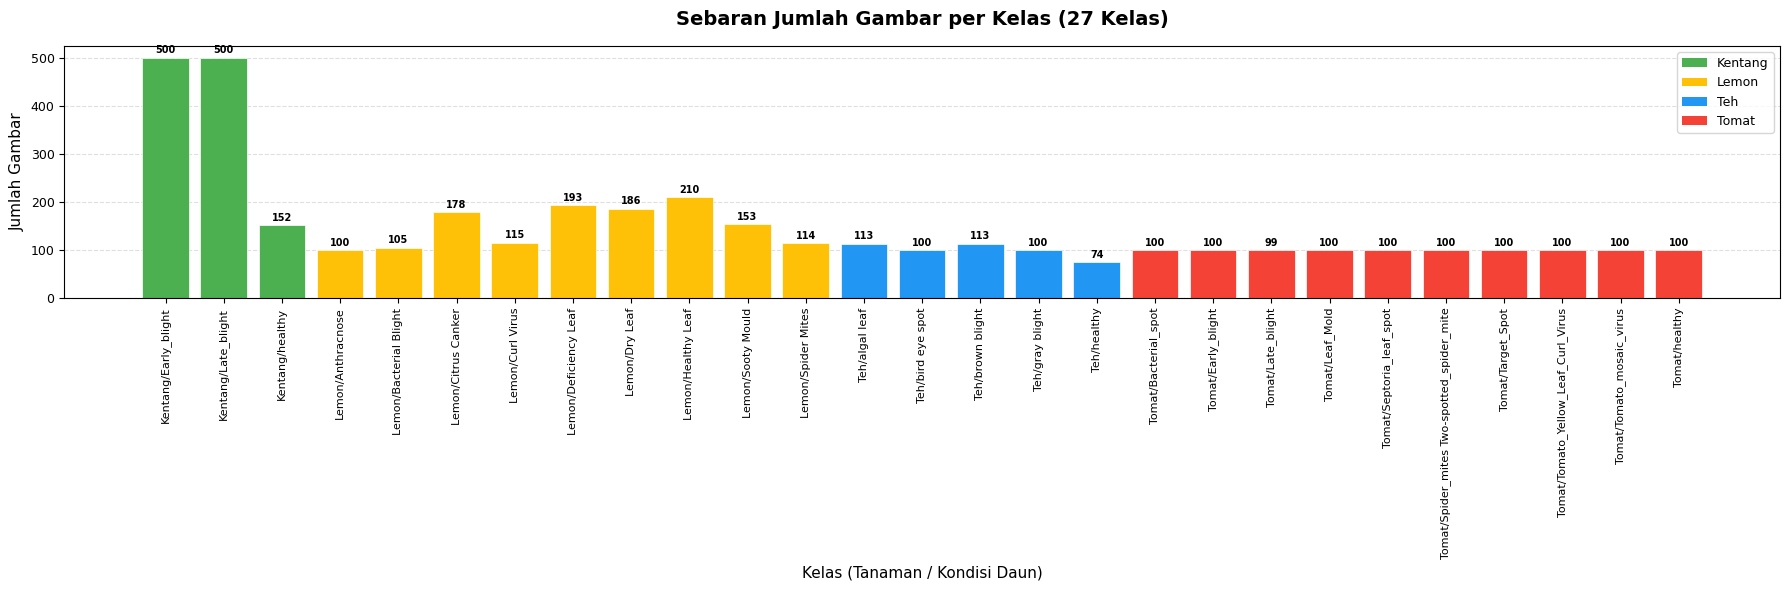


 Visualisasi sebaran kelas selesai.
Bar chart membantu mengidentifikasi class imbalance antar kelas.


In [ ]:
# ============================================================
# CELL 4 — Eksplorasi Data (EDA)
# Menampilkan jumlah total gambar, sebaran kelas per tanaman, dan visualisasi bar chart untuk analisis data imbalance
# ============================================================

import os
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Path dataset raw hasil ekstraksi
RAW_PATH = "/content/MACHINE LEARNING_IFEST6.0_belum kepikiran/dataset/raw"

# Tanaman yang dianalisis
PLANTS = ["Kentang", "Lemon", "Teh", "Tomat"]

# Dictionary untuk menyimpan jumlah gambar per kelas
class_counts = {}
plant_totals = {}

print("=" * 60)
print("EKSPLORASI DATA — SEBARAN KELAS PER TANAMAN")
print("=" * 60)

total_images = 0

for plant in PLANTS:
    plant_path = os.path.join(RAW_PATH, plant)

    # Cek apakah folder tanaman tersedia
    if not os.path.exists(plant_path):
        print(f"Folder tidak ditemukan: {plant_path}")
        continue

    diseases = sorted(os.listdir(plant_path))
    plant_total = 0

    print(f"\n {plant}:")
    print("-" * 40)

    for disease in diseases:
        disease_path = os.path.join(plant_path, disease)
        if not os.path.isdir(disease_path):
            continue

        # Hitung jumlah file gambar
        images = [
            f for f in os.listdir(disease_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
        ]
        count = len(images)
        label = f"{plant}/{disease}"
        class_counts[label] = count
        plant_total += count

        print(f" {disease:<30} : {count:>5} gambar")

    plant_totals[plant] = plant_total
    total_images += plant_total
    print(f" {'─'*40}")
    print(f"Subtotal {plant:<26} : {plant_total:>5} gambar")

print("\n" + "=" * 60)
print(f"TOTAL KESELURUHAN GAMBAR    : {total_images:>6} gambar")
print(f"TOTAL KELAS                 : {len(class_counts):>6} kelas")
print("=" * 60)

# ── Visualisasi Bar Chart Sebaran Kelas ──────────────────────
# Menampilkan distribusi gambar per kelas untuk memudahkan
# identifikasi kelas yang imbalanced (tidak seimbang).

labels = list(class_counts.keys())
counts = list(class_counts.values())

# Warna berbeda per tanaman
color_map = {
    "Kentang": "#4CAF50",
    "Lemon":   "#FFC107",
    "Teh":     "#2196F3",
    "Tomat":   "#F44336"
}

bar_colors = []
for label in labels:
    plant = label.split("/")[0]
    bar_colors.append(color_map.get(plant, "#9E9E9E"))

fig, ax = plt.subplots(figsize=(18, 6))

bars = ax.bar(labels, counts, color=bar_colors, edgecolor='white', linewidth=0.5)

# Tambahkan label jumlah di atas setiap bar
for bar, count in zip(bars, counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        str(count),
        ha='center', va='bottom', fontsize=7, fontweight='bold'
    )

# Rotasi label sumbu X agar tidak tumpang tindih (27 kelas)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(fontsize=9)

ax.set_title("Sebaran Jumlah Gambar per Kelas (27 Kelas)", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Kelas (Tanaman / Kondisi Daun)", fontsize=11)
ax.set_ylabel("Jumlah Gambar", fontsize=11)

# Legend tanaman
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=color_map[p], label=p) for p in PLANTS if p in color_map]
ax.legend(handles=legend_elements, loc='upper right', fontsize=9)

ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("sebaran_kelas.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n Visualisasi sebaran kelas selesai.")
print("Bar chart membantu mengidentifikasi class imbalance antar kelas.")

In [ ]:
# ============================================================
# CELL 5 — Split Dataset (Train / Val / Test)
# Menggunakan library split-folders agar proses split lebih bersih dan stratified (proporsional per kelas), BUKAN manual
#
# Alasan split per tanaman (bukan global):
# Memastikan proporsi tiap kelas tetap seimbang di setiap subset, khususnya jika ada perbedaan jumlah gambar antar tanaman (class imbalance antar grup tanaman)
#
# Rasio: 80% Train | 10% Val | 10% Test
# Random seed dikunci agar hasil split bisa direproduksi
# ============================================================

!pip install split-folders -q

import splitfolders
import os
import shutil

# Path dataset raw dan tujuan split
RAW_PATH   = "/content/MACHINE LEARNING_IFEST6.0_belum kepikiran/dataset/raw"
SPLIT_PATH = "/content/dataset/split"

# Tanaman yang ada di dataset
PLANTS = ["Kentang", "Lemon", "Teh", "Tomat"]

# Random seed dikunci agar hasil split selalu konsisten/reproducible
SEED = 42

# Buat folder tujuan split
os.makedirs(SPLIT_PATH, exist_ok=True)

print("=" * 60)
print("MEMULAI PROSES SPLIT DATASET")
print(f"Sumber : {RAW_PATH}")
print(f"Tujuan : {SPLIT_PATH}")
print(f"Rasio  : Train 80% | Val 10% | Test 10%")
print(f"Seed   : {SEED}")
print("=" * 60)

for plant in PLANTS:
    plant_src  = os.path.join(RAW_PATH, plant)
    plant_dst  = os.path.join(SPLIT_PATH, "train", plant)   # Cek apakah sudah ada

    if not os.path.exists(plant_src):
        print(f"Folder tanaman tidak ditemukan, dilewati: {plant_src}")
        continue

    # Folder output sementara per tanaman
    plant_output = os.path.join(SPLIT_PATH, f"_tmp_{plant}")

    print(f"\n Memproses: {plant} ...")

    try:
        # split-folders akan membuat subfolder output/train, output/val, output/test
        splitfolders.ratio(
            plant_src,
            output=plant_output,
            seed=SEED,
            ratio=(0.8, 0.1, 0.1),  # train, val, test
            group_prefix=None,
            move=False              # copy, bukan move — agar data raw aman
        )

        # Memindahkan hasil split dari folder tmp ke struktur akhir
        for subset in ["train", "val", "test"]:
            src_subset = os.path.join(plant_output, subset)
            dst_subset = os.path.join(SPLIT_PATH, subset, plant)

            if os.path.exists(src_subset):
                os.makedirs(dst_subset, exist_ok=True)
                # Memindahkan setiap subfolder kelas (penyakit)
                for disease_folder in os.listdir(src_subset):
                    s = os.path.join(src_subset, disease_folder)
                    d = os.path.join(dst_subset, disease_folder)
                    if os.path.isdir(s):
                        if os.path.exists(d):
                            shutil.rmtree(d)
                        shutil.copytree(s, d)

        # Menghapus folder tmp setelah dipindahkan
        shutil.rmtree(plant_output)
        print(f" {plant} berhasil di-split!")

    except Exception as e:
        print(f"Error saat memproses {plant}: {e}")

# Verifikasi hasil split
print("\n" + "=" * 60)
print("VERIFIKASI HASIL SPLIT")
print("=" * 60)

for subset in ["train", "val", "test"]:
    subset_path = os.path.join(SPLIT_PATH, subset)
    total = 0
    print(f"\n {subset.upper()}/")
    if os.path.exists(subset_path):
        for plant in sorted(os.listdir(subset_path)):
            plant_path = os.path.join(subset_path, plant)
            if os.path.isdir(plant_path):
                plant_count = sum(
                    len(files)
                    for _, _, files in os.walk(plant_path)
                )
                total += plant_count
                print(f" {plant:<10} : {plant_count:>5} gambar")
    print(f" {'─'*30}")
    print(f"Subtotal : {total:>5} gambar")

print("\n Split dataset selesai! Struktur folder siap digunakan.")

MEMULAI PROSES SPLIT DATASET
Sumber : /content/MACHINE LEARNING_IFEST6.0_belum kepikiran/dataset/raw
Tujuan : /content/dataset/split
Rasio  : Train 80% | Val 10% | Test 10%
Seed   : 42

 Memproses: Kentang ...


Copying files: 1152 files [00:01, 1021.67 files/s]


 Kentang berhasil di-split!

 Memproses: Lemon ...


Copying files: 1354 files [00:06, 219.37 files/s]


 Lemon berhasil di-split!

 Memproses: Teh ...


Copying files: 500 files [00:04, 121.02 files/s]


 Teh berhasil di-split!

 Memproses: Tomat ...


Copying files: 999 files [00:00, 6117.56 files/s]


 Tomat berhasil di-split!

VERIFIKASI HASIL SPLIT

 TRAIN/
 Kentang    :   921 gambar
 Lemon      :  1081 gambar
 Teh        :   399 gambar
 Tomat      :   799 gambar
 ──────────────────────────────
Subtotal :  3200 gambar

 VAL/
 Kentang    :   115 gambar
 Lemon      :   132 gambar
 Teh        :    49 gambar
 Tomat      :    99 gambar
 ──────────────────────────────
Subtotal :   395 gambar

 TEST/
 Kentang    :   116 gambar
 Lemon      :   141 gambar
 Teh        :    52 gambar
 Tomat      :   101 gambar
 ──────────────────────────────
Subtotal :   410 gambar

 Split dataset selesai! Struktur folder siap digunakan.


In [ ]:
# ============================================================
# CELL 6 — Preprocessing dan Augmentasi Data
#
# Tiga objek ImageDataGenerator dibuat dengan peran berbeda:
#   - train_datagen : augmentasi LENGKAP → untuk mencegah overfitting
#   - val_datagen   : hanya rescale → untuk evaluasi murni
#   - test_datagen  : hanya rescale → untuk prediksi apa adanya
#
# Alasan augmentasi hanya di train:
# Val dan test digunakan untuk mengukur kemampuan model pada data asli/nyata. Jika diaugmentasi, hasilnya bias karena gambar yang dievaluasi bukan gambar "apa adanya"
# ============================================================

from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Path split dataset
SPLIT_PATH  = "/content/dataset/split"
TRAIN_PATH  = f"{SPLIT_PATH}/train"
VAL_PATH    = f"{SPLIT_PATH}/val"
TEST_PATH   = f"{SPLIT_PATH}/test"

IMG_SIZE    = (150, 150)  # Target size: 150x150 untuk keseimbangan detail & efisiensi komputasi
BATCH_SIZE  = 32          # Batch 32: standar yang efisien untuk training dari nol

# 1. ImageDataGenerator
# rescale=1./255 digunakan untuk menormalisasi nilai piksel dari rentang [0, 255] ke rentang [0, 1] agar proses komputasi gradient lebih stabil dan konvergensi lebih cepat

train_datagen = ImageDataGenerator(
    rescale=1./255,           # Normalisasi piksel ke [0,1], wajib untuk menjaga stabilitas gradient
    rotation_range=40,        # Rotasi ±40° untuk simulasi sudut pengambilan foto daun di lapangan
    width_shift_range=0.2,    # Geser horizontal 20% untuk simulasi posisi daun yang tidak simetris
    height_shift_range=0.2,   # Geser vertikal 20% untuk variasi posisi daun
    shear_range=0.2,          # Transformasi shear untuk memperkaya variasi geometri daun
    zoom_range=0.2,           # Zoom ±20% untuk simulasi jarak foto yang berbeda-beda
    horizontal_flip=True,     # Flip horizontal agar daun bisa difoto dari kiri/kanan
    fill_mode='nearest'       # Isi piksel kosong dengan nilai tetangga terdekat
)

val_datagen = ImageDataGenerator(
    rescale=1./255            # Hanya normalisasi — evaluasi tanpa augmentasi (data apa adanya)
)

test_datagen = ImageDataGenerator(
    rescale=1./255            # Hanya normalisasi — prediksi pada data asli tanpa modifikasi
)

# 2. Generator (.flow_from_directory)

train_generator = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=IMG_SIZE,      # Resize semua gambar ke 150x150
    batch_size=BATCH_SIZE,
    class_mode='categorical',  # One-hot encoding untuk klasifikasi multi-kelas (27 kelas)
    shuffle=True               # Wajib di-shuffle agar model tidak belajar urutan data
)

val_generator = val_datagen.flow_from_directory(
    VAL_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False              # Tidak di-shuffle agar evaluasi konsisten
)

test_generator = test_datagen.flow_from_directory(
    TEST_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False              # Wajib False agar urutan prediksi di confusion matrix tidak berantakan
)

# 3. Info Generator
print("=" * 60)
print("GENERATOR BERHASIL DIBUAT")
print("=" * 60)
print(f"Train  : {train_generator.samples:>5} gambar | {train_generator.num_classes} kelas")
print(f"Val    : {val_generator.samples:>5} gambar | {val_generator.num_classes} kelas")
print(f"Test   : {test_generator.samples:>5} gambar | {test_generator.num_classes} kelas")
print(f"\n Kamus Kelas (27 kelas):")
for cls, idx in sorted(train_generator.class_indices.items(), key=lambda x: x[1]):
    print(f"   [{idx:>2}] {cls}")

Found 3200 images belonging to 4 classes.
Found 395 images belonging to 4 classes.
Found 410 images belonging to 4 classes.
GENERATOR BERHASIL DIBUAT
Train  :  3200 gambar | 4 kelas
Val    :   395 gambar | 4 kelas
Test   :   410 gambar | 4 kelas

 Kamus Kelas (27 kelas):
   [ 0] Kentang
   [ 1] Lemon
   [ 2] Teh
   [ 3] Tomat


In [ ]:
# ============================================================
# CELL 7 — Arsitektur CNN
# Desain arsitektur mengikuti prinsip gradual feature learning:
#   Layer 1-2 → Deteksi fitur low-level (tepi, garis, dan warna)
#   Layer 3-4 → Deteksi fitur high-level (tekstur dan pola penyakit)
#
# Keputusan desain:
#   • 4 layer konvolusi: cukup dalam untuk mengenali penyakit
#     daun, tidak berlebihan sehingga menghindari overfitting
#     dan tetap efisien untuk dilatih dari nol.
#   • Filter 32→64→128→256: semakin dalam, semakin banyak
#     fitur kompleks yang bisa dikenali.
#   • padding='same': agar informasi di tepi gambar tidak
#     terbuang saat proses konvolusi di layer awal.
#   • BatchNorm SEBELUM ReLU: menstabilkan distribusi input
#     ke fungsi aktivasi → konvergensi lebih cepat sejak awal.
#   • kernel_initializer='he_normal': mencegah exploding/
#     vanishing gradient, cocok digunakan bersama ReLU.
#   • MaxPooling (2,2): fokus ke fitur dominan, kurangi
#     dimensi agar tidak RAM-heavy.
#   • Dropout 0.5: mencegah model bergantung pada neuron
#     tertentu saja agar generalisasi lebih baik.
# ============================================================

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Conv2D, BatchNormalization, Activation,
    MaxPooling2D, Flatten, Dense, Dropout
)

NUM_CLASSES = train_generator.num_classes  # 27 kelas

model = Sequential([

    # ── TAHAP EKSTRAKSI FITUR ─────────────────────────────────

    # LAYER 1 — Deteksi fitur primitif: tepi, garis, gradien warna
    Conv2D(32, (3, 3), padding='same', kernel_initializer='he_normal',
           input_shape=(150, 150, 3)),
    # BatchNorm SEBELUM ReLU agar distribusi input ke aktivasi stabil
    BatchNormalization(),
    Activation('relu'),         # ReLU: cegah vanishing gradient, training lebih cepat
    MaxPooling2D((2, 2)),       # Mengurangi dimensi dan mempertahankan fitur dominan

    # LAYER 2 — Deteksi kombinasi tepi: sudut, kurva sederhana
    Conv2D(64, (3, 3), padding='same', kernel_initializer='he_normal'),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2, 2)),

    # LAYER 3 — Deteksi tekstur: bercak, pola permukaan daun
    Conv2D(128, (3, 3), padding='same', kernel_initializer='he_normal'),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2, 2)),

    # LAYER 4 — Deteksi pola kompleks: bentuk lesi, area nekrosis
    Conv2D(256, (3, 3), padding='same', kernel_initializer='he_normal'),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2, 2)),

    # TAHAP KLASIFIKASI
    # Ubah output konvolusi (3D) menjadi vektor 1D
    Flatten(),

    # Dense 512 neuron untuk mencari hubungan non-linear antar fitur
    Dense(512, kernel_initializer='he_normal'),
    BatchNormalization(),
    Activation('relu'),

    # Dropout 0.5 — regularisasi: memaksa model belajar fitur yang robust, bukan bergantung pada neuron spesifik untuk mencegah overfitting
    Dropout(0.5),

    # OUTPUT LAYER
    # 27 neuron = 27 kelas penyakit
    # Softmax: mengonversi logit menjadi distribusi probabilitas dan memilih kelas dengan probabilitas tertinggi
    Dense(NUM_CLASSES, activation='softmax')
])

# Menampilkan ringkasan arsitektur model
model.summary()

print("\n Arsitektur CNN berhasil dibangun.")
print(f"Input shape  : (150, 150, 3)")
print(f"Output shape : {NUM_CLASSES} kelas (Softmax)")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 18, 18, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    10,617,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 11,011,780 (42.01 MB)

 Trainable params: 11,009,796 (42.00 MB)

 Non-trainable params: 1,984 (7.75 KB)


 Arsitektur CNN berhasil dibangun.
Input shape  : (150, 150, 3)
Output shape : 4 kelas (Softmax)


In [ ]:
# ============================================================
# CELL 8 — Training Model
#
# Konfigurasi training:
#   • Optimizer Adam (lr=0.001): adaptive learning rate, konvergen lebih cepat dibanding SGD biasa.
#   • Loss Categorical Crossentropy: standar untuk klasifikasi multi-kelas dengan output one-hot encoding.
#   • EarlyStopping (patience=5, monitor='val_loss'): menghentikan training jika val_loss tidak membaik selama 5 epoch berturut-turut unutk mencegah overfitting & hemat waktu.
#   • restore_best_weights=True: pastikan bobot yang dipakai adalah bobot terbaik, bukan bobot di epoch terakhir.
#   • ModelCheckpoint: menyimpan model terbaik secara otomatis ke Drive sehingga tidak hilang jika sesi Colab habis.
# ============================================================

import os
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# 1. Callback
# EarlyStopping: monitor val_loss, berhenti jika tidak membaik
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,               # Toleransi 5 epoch tanpa perbaikan
    restore_best_weights=True,# Mengembalikan bobot terbaik setelah berhenti
    verbose=1
)

# Path simpan model terbaik di Google Drive
MODEL_SAVE_PATH = "/content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5"
os.makedirs(os.path.dirname(MODEL_SAVE_PATH), exist_ok=True)

# ModelCheckpoint: simpan model terbaik berdasarkan val_accuracy
model_checkpoint = ModelCheckpoint(
    filepath=MODEL_SAVE_PATH,
    monitor='val_accuracy',
    save_best_only=True,      # Hanya menyimpan jika performa lebih baik dari sebelumnya
    verbose=1
)

# 2. Compile Model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',  # Cocok untuk klasifikasi multi-kelas one-hot
    metrics=['accuracy']
)

print("Model berhasil di-compile.")
print(f"Optimizer : Adam (lr=0.001)")
print(f"Loss      : Categorical Crossentropy")
print(f"Metrics   : Accuracy")

# 3. Training (model.fit)
print("\n Memulai Training...")
print("=" * 60)

history = model.fit(
    train_generator,
    epochs=50,                        # Maksimal 50 epoch (EarlyStopping akan berhenti lebih awal)
    batch_size=32,
    validation_data=val_generator,
    callbacks=[early_stop, model_checkpoint],
    verbose=1
)

print("\n" + "=" * 60)
print("Training selesai!")
print(f"Epoch terbaik disimpan di: {MODEL_SAVE_PATH}")

Model berhasil di-compile.
Optimizer : Adam (lr=0.001)
Loss      : Categorical Crossentropy
Metrics   : Accuracy

 Memulai Training...
Epoch 1/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7661 - loss: 0.6211
Epoch 1: val_accuracy improved from None to 0.26329, saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5



Epoch 1: finished saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5
100/100 ━━━━━━━━━━━━━━━━━━━━ 203s 2s/step - accuracy: 0.8400 - loss: 0.3955 - val_accuracy: 0.2633 - val_loss: 5.1528
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9035 - loss: 0.2433
Epoch 2: val_accuracy improved from 0.26329 to 0.69367, saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5



Epoch 2: finished saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5
100/100 ━━━━━━━━━━━━━━━━━━━━ 203s 2s/step - accuracy: 0.8959 - loss: 0.2514 - val_accuracy: 0.6937 - val_loss: 0.8316
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9162 - loss: 0.2090
Epoch 3: val_accuracy improved from 0.69367 to 0.94430, saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5



Epoch 3: finished saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5
100/100 ━━━━━━━━━━━━━━━━━━━━ 203s 2s/step - accuracy: 0.9184 - loss: 0.2086 - val_accuracy: 0.9443 - val_loss: 0.1594
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9224 - loss: 0.1783
Epoch 4: val_accuracy did not improve from 0.94430
100/100 ━━━━━━━━━━━━━━━━━━━━ 196s 2s/step - accuracy: 0.9225 - loss: 0.1810 - val_accuracy: 0.8785 - val_loss: 0.4544
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9414 - loss: 0.1555
Epoch 5: val_accuracy improved from 0.94430 to 0.95696, saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5



Epoch 5: finished saving model to /content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/models/best_model.h5
100/100 ━━━━━━━━━━━━━━━━━━━━ 194s 2s/step - accuracy: 0.9384 - loss: 0.1641 - val_accuracy: 0.9570 - val_loss: 0.1588
Epoch 6/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9381 - loss: 0.1534
Epoch 6: val_accuracy did not improve from 0.95696
100/100 ━━━━━━━━━━━━━━━━━━━━ 203s 2s/step - accuracy: 0.9356 - loss: 0.1579 - val_accuracy: 0.8304 - val_loss: 0.7933
Epoch 7/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9356 - loss: 0.1529
Epoch 7: val_accuracy did not improve from 0.95696
100/100 ━━━━━━━━━━━━━━━━━━━━ 256s 2s/step - accuracy: 0.9406 - loss: 0.1456 - val_accuracy: 0.7848 - val_loss: 0.7779
Epoch 8/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9469 - loss: 0.1285
Epoch 8: val_accuracy did not improve from 0.95696
100/100 ━━━━━━━━━━━━━━━━━━━━ 195s 2s/step - accuracy: 0.9519 - loss: 0.1225 - val_accuracy: 0.9139 - val_loss: 0.2627

EVALUASI MODEL PADA DATA TEST
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 522ms/step - accuracy: 0.9463 - loss: 0.1608

 Test Loss   : 0.1608
 Test Accuracy : 94.63%


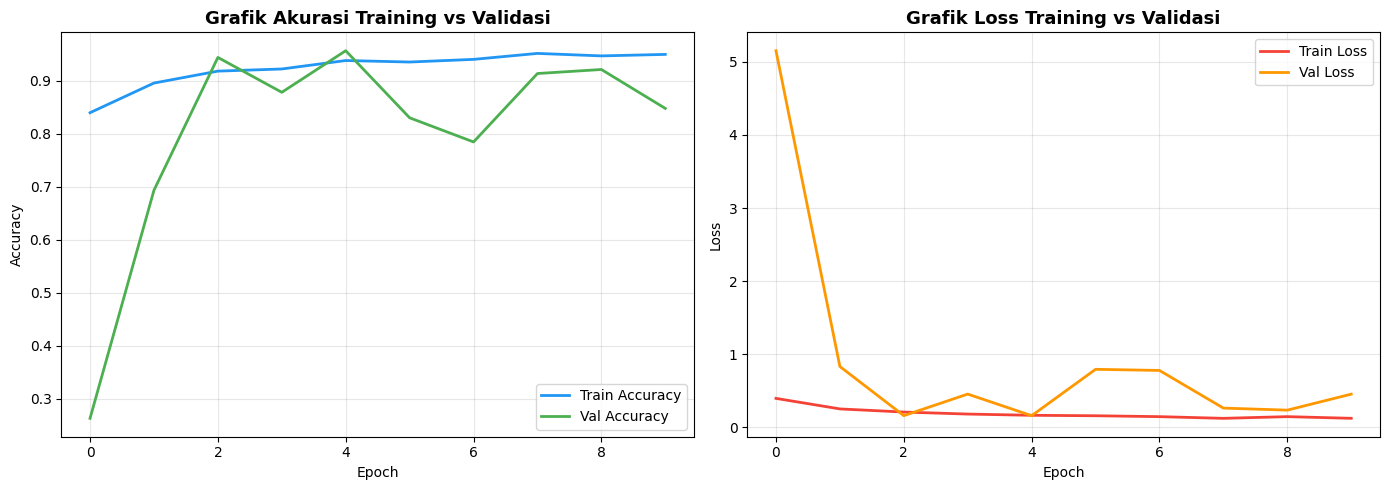

13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 577ms/step


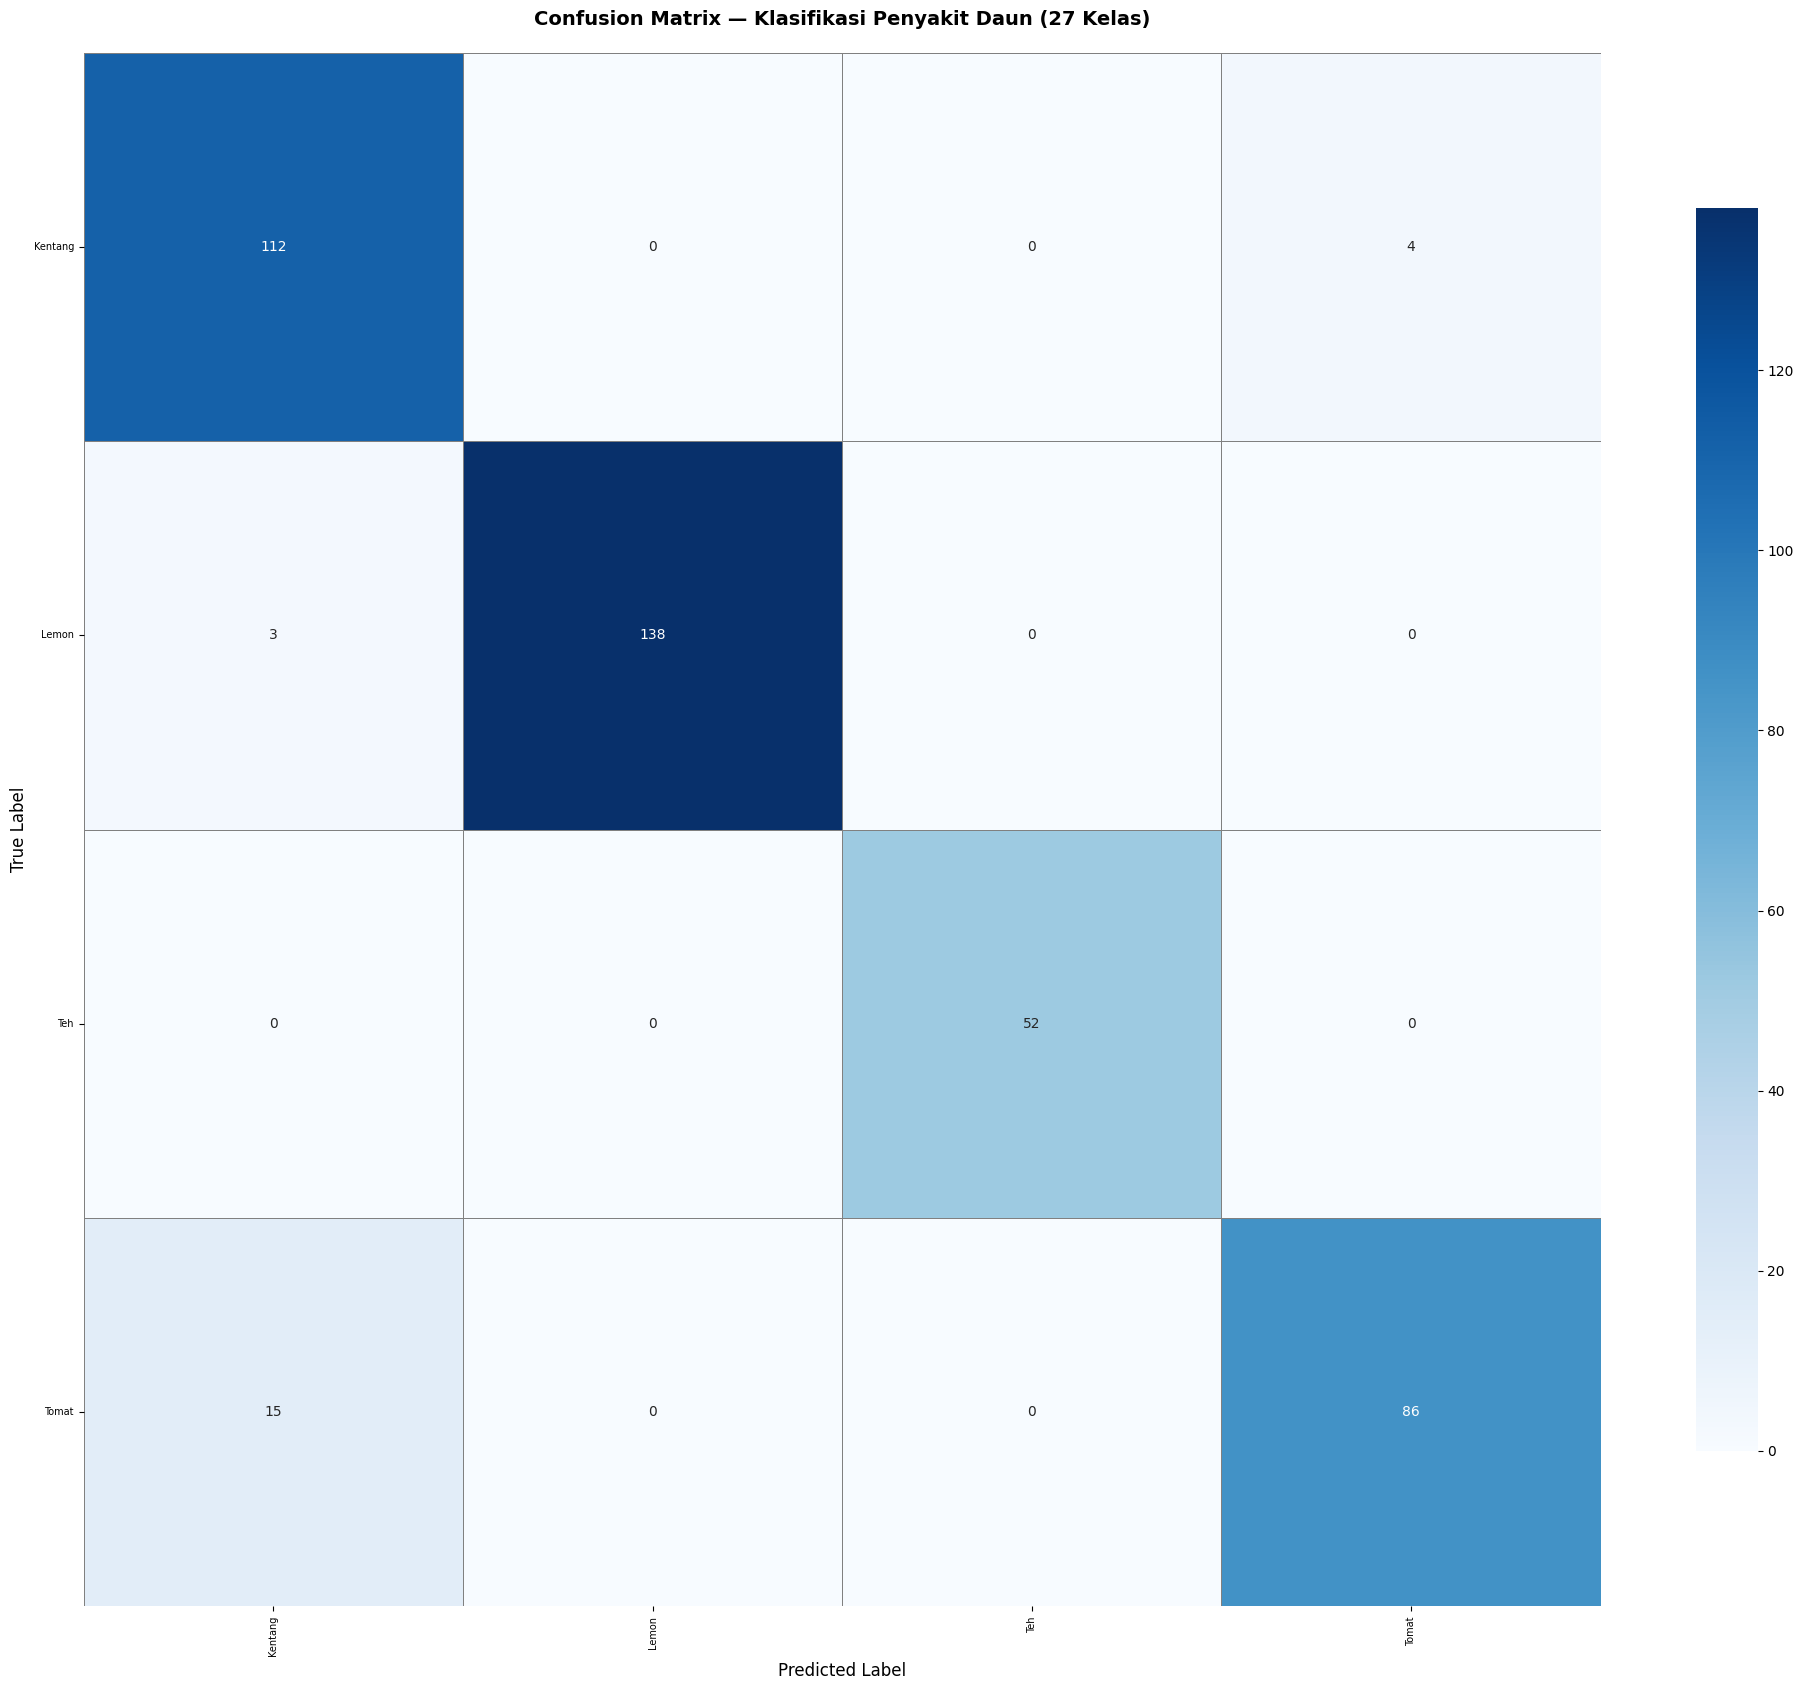


 Diagonal = prediksi benar | Off-diagonal = salah klasifikasi

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Kentang       0.86      0.97      0.91       116
       Lemon       1.00      0.98      0.99       141
         Teh       1.00      1.00      1.00        52
       Tomat       0.96      0.85      0.90       101

    accuracy                           0.95       410
   macro avg       0.95      0.95      0.95       410
weighted avg       0.95      0.95      0.95       410



In [ ]:
# ============================================================
# CELL 9 — Evaluasi Model
# Menampilkan:
#   1. Akurasi pada data test
#   2. Grafik akurasi & loss (train vs val)
#   3. Confusion Matrix (Heatmap) untuk 27 kelas
#   4. Classification Report
#
# Alasan menggunakan Heatmap untuk Confusion Matrix:
# Dengan 27 kelas, confusion matrix teks sangat panjang dan sulit dibaca. Heatmap memudahkan untuk melihat secara visual penyakit mana yang sering tertukar oleh model
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Evaluasi pada Data Test
print("=" * 60)
print("EVALUASI MODEL PADA DATA TEST")
print("=" * 60)

test_loss, test_acc = model.evaluate(test_generator, verbose=1)
print(f"\n Test Loss   : {test_loss:.4f}")
print(f" Test Accuracy : {test_acc * 100:.2f}%")

# 2. Grafik Akurasi & Loss (Train vs Validation)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Akurasi
axes[0].plot(history.history['accuracy'],     label='Train Accuracy',  color='#2196F3', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy',    color='#4CAF50', linewidth=2)
axes[0].set_title('Grafik Akurasi Training vs Validasi', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(history.history['loss'],     label='Train Loss',  color='#F44336', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Val Loss',    color='#FF9800', linewidth=2)
axes[1].set_title('Grafik Loss Training vs Validasi', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("training_history.png", dpi=150, bbox_inches='tight')
plt.show()

# 3. Prediksi & Label Asli

# Reset generator agar prediksi mulai dari awal (penting: shuffle=False)
test_generator.reset()

y_pred_probs = model.predict(test_generator, verbose=1)
y_pred       = np.argmax(y_pred_probs, axis=1)   # Kelas prediksi
y_true       = test_generator.classes            # Label asli

# Nama kelas dari generator
class_labels = list(test_generator.class_indices.keys())

# 4. Confusion Matrix Heatmap
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(20, 17))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels,
    linewidths=0.5,
    linecolor='gray',
    cbar_kws={'shrink': 0.8}
)

plt.title('Confusion Matrix — Klasifikasi Penyakit Daun (27 Kelas)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label',      fontsize=12)
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0,  fontsize=7)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n Diagonal = prediksi benar | Off-diagonal = salah klasifikasi")

# 5. Classification Report
print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_true, y_pred, target_names=class_labels))

In [ ]:
# ============================================================
# CELL 10 — Backup Split Dataset ke Google Drive
#
# PERHATIAN: SELURUH BARIS KODE DI BAWAH INI DINONAKTIFKAN (di-comment) agar TIDAK otomatis tereksekusi.
#
# Fungsi cell ini:
#   → Mengompres folder split hasil Cell 5 menjadi file .zip
#   → Menyalin file .zip tersebut ke Google Drive sebagai backup
#
# Cara menggunakan (jika diperlukan):
#   1. Hapus tanda '#' di depan setiap baris kode di bawah
#   2. Jalankan cell ini SETELAH Cell 5 selesai
#   3. Pastikan Google Drive sudah ter-mount (Cell 2)
#
# Catatan: Proses ini membutuhkan waktu cukup lama tergantung ukuran dataset. Hanya perlu dijalankan satu kali untuk backup.
# ============================================================

# import os
# import shutil

# # Path sumber folder split di lokal Colab
# SPLIT_PATH = "/content/dataset/split"

# # Nama file backup
# BACKUP_NAME = "split_dataset_backup"

# # Path tujuan backup di Google Drive
# DRIVE_BACKUP_PATH = "/content/drive/MyDrive/MACHINE LEARNING_IFEST6.0_belum kepikiran/dataset/split"

# print("Mengompres folder split menjadi .zip ...")
# # Kompres folder split menjadi .zip di direktori /content
# shutil.make_archive(
#     base_name=f"/content/{BACKUP_NAME}",  # Nama output (tanpa ekstensi)
#     format='zip',                          # Format: zip
#     root_dir="/content/dataset",           # Root dari path yang dikompres
#     base_dir="split"                       # Folder yang dikompres
# )
# print(f"Kompresi selesai: /content/{BACKUP_NAME}.zip")

# # Buat folder tujuan di Drive jika belum ada
# os.makedirs(DRIVE_BACKUP_PATH, exist_ok=True)

# # Salin file .zip ke Google Drive
# print(f"\n Menyalin ke Google Drive: {DRIVE_BACKUP_PATH} ...")
# shutil.copy(
#     f"/content/{BACKUP_NAME}.zip",
#     f"{DRIVE_BACKUP_PATH}/{BACKUP_NAME}.zip"
# )
# print(f"Backup berhasil disimpan ke Drive!")
# print(f"Path : {DRIVE_BACKUP_PATH}/{BACKUP_NAME}.zip")

In [ ]:
# ============================================================
# CELL 11 — Menyimpan Model Final & Download
#
# Cell ini menyimpan bobot final model yang sudah dilatih dan menyiapkan file label (kamus kelas) untuk keperluan inferensi/deployment di luar Colab.
#
# Dua file yang dihasilkan:
#   1. model_final_ifest.h5  → Bobot model CNN final
#   2. class_indices.json    → Kamus label (index → nama kelas)
#
# Catatan untuk juri:
# Aktifkan baris-baris code di bawah jika ingin mengunduh file model dan label secara otomatis ke perangkat lokal.
# ============================================================

# import json
# from google.colab import files

# # Menyimpan Model Final
# MODEL_FINAL_PATH = "model_final_ifest.h5"
# model.save(MODEL_FINAL_PATH)
# print(f"Model final berhasil disimpan: {MODEL_FINAL_PATH}")

# # Simpan Kamus Label (class_indices.json)
# # Membuat kamus dari class_indices generator dengan {nama_kelas: index}
# # Membalik kamus agar format menjadi {index: nama_kelas} untuk kemudahan inferensi
# class_indices = train_generator.class_indices
# index_to_class = {str(v): k for k, v in class_indices.items()}

# # Menyimpan ke file JSON menggunakan library json
# with open("class_indices.json", "w") as f:
#     json.dump(index_to_class, f, indent=4)

# print(f"Kamus label berhasil disimpan: class_indices.json")
# print(f"Total kelas: {len(index_to_class)} kelas")

# # Preview isi kamus
# print("\n Preview class_indices.json:")
# for idx, cls in sorted(index_to_class.items(), key=lambda x: int(x[0])):
#     print(f"   [{idx:>2}] → {cls}")

# # Download File
# # Aktifkan baris di bawah ini jika ingin mengunduh file model dan label secara otomatis ke perangkat lokal.
# files.download('model_final_ifest.h5')
# files.download('class_indices.json')

#Hasil Analisis dan Kesimpulan
Berdasarkan hasil pengujian, model CNN yang dibangun oleh kami berhasil mencapai performa yang bagus dengan akurasi total sebesar 95%. Capaian ini menunjukkan bahwa arsitektur yang kami rancang mampu melakukan generalisasi fitur dengan sangat baik, terutama pada komoditas Teh dan Lemon yang memiliki skor F1 masing-masing sebesar 1.00 dan 0.99. Hal ini menunjukkan bahwa model memiliki kemampuan diskriminasi yang sempurna terhadap karakteristik morfologi daun teh dan lemon.

Namun, hasil pada confusion matrix menunjukkan adanya misklasifikasi tanaman keluarga Solanaceae. Ditemukan 15 data Tomat yang terdeteksi sebagai Kentang. Hal ini secara ilmiah sangat wajar terjadi karena kedua tanaman tersebut berasal dari genus yang sama (Solanum). Secara morfologi, daun tomat dan kentang memiliki kemiripan bentuk gerigi dan tekstur permukaan yang identik. Selain itu, pola visual dari gejala penyakit seperti Early Blight dan Late Blight pada kedua tanaman ini memiliki karakteristik bercak cokelat konsentris yang hampir tidak bisa dibedakan hanya dari fitur visual kasar. Hal inilah yang menyebabkan model terkadang lebih fokus pada pola penyakitnya daripada struktur tanaman inangnya.

Secara keseluruhan, model tetap mampu mempertahankan performa yang stabil dan kompetitif di angka 95%. Temuan ini justru mempertegas kekuatan model dalam mendeteksi pola penyakit secara general, sekaligus memberikan landasan bagi kami untuk melakukan optimasi pada aspek kedalaman arsitektur dan augmentasi data yang lebih spesifik guna menyempurnakan kemampuan diskriminasi antar tanaman yang berkerabat dekat di masa mendatang.